# 01 · Audit, cible `default_60m` et exploration
Le pipeline est dans `src/data_prep.py` (relancer : `python src/data_prep.py`). Ce notebook lit ses sorties.

In [1]:
import sys, json; sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200)
audit = json.load(open('../data/processed/audit_donnees.json', encoding='utf-8'))
audit

{'lignes_brutes': 1236084,
 'statuts_bruts': {'P I F': 858229,
  'CHGOFF': 178800,
  'CANCLD': 149017,
  'EXEMPT': 49949,
  'autre (ligne décalée / valeur parasite)': 47,
  'COMMIT': 42},
 'ecriture_PIF_variantes': ['P I F'],
 'lignes_statut_invalide_retirees': 47,
 'doublons_exacts_retires': 1414,
 'sans_FirstDisbursementDate_total': 149575,
 'sans_FirstDisbursementDate_par_statut': {'CANCLD': 147990,
  'P I F': 1428,
  'CHGOFF': 114,
  'COMMIT': 42,
  'EXEMPT': 1},
 'retires_statut_non_resolu': {'EXEMPT': 49929},
 'date_du_fichier': '2026-09-30',
 'retires_moins_de_60_mois': 122,
 'defauts_status_chgoff_apres_60m_comptes_zero': 66652,
 'id_haches_en_double_retires': 2426,
 'retires_hors_2000_2016': 122538,
 'blocs': {'train': {'annees': '2000-2012',
   'lignes': 723663,
   'taux_defaut': 0.1348,
   'defauts': 97535},
  'val': {'annees': '2013-2014',
   'lignes': 82384,
   'taux_defaut': 0.0357,
   'defauts': 2939},
  'test': {'annees': '2015-2016',
   'lignes': 103986,
   'taux_defau

In [2]:
pd.read_csv('../data/processed/taux_defaut_par_bloc.csv', index_col=0)

,annees,lignes,taux_defaut,defauts
train,2000-2012,723663,0.1348,97535
val,2013-2014,82384,0.0357,2939
test,2015-2016,103986,0.0425,4415


**Constats** : statuts SBA = P I F, CHGOFF, CANCLD, EXEMPT, COMMIT (+ 47 lignes décalées retirées) ; 1 414 doublons exacts ; lignes sans `FirstDisbursementDate` écartées (surtout CANCLD) ; EXEMPT non résolus retirés ; le taux de défaut baisse fortement après 2012 (crise de 2008 dans l'entraînement).

**Fuite détectée** : la durée exacte `TermInMonths` est altérée après l'octroi pour les prêts en défaut.

In [3]:
tr = pd.read_parquet('../data/processed/train.parquet')
g = tr.groupby('TermInMonths').default_60m.agg(['mean','size'])
g[g['size']>1000].round(3).T

TermInMonths,1,2,3,4,5,6,7,8,9,10,...,168,180,204,216,240,252,264,276,288,300
mean,0.245,0.221,0.213,0.245,0.252,0.174,0.212,0.249,0.233,0.256,...,0.01,0.001,0.012,0.013,0.001,0.008,0.015,0.01,0.004,0.0
size,1747.000,1955.000,2019.000,1982.000,1894.000,2323.000,1790.000,1564.000,1592.000,1426.000,...,1062.00,12162.000,1043.000,1088.000,15174.000,1370.000,1540.000,1762.00,2061.000,34153.0


In [4]:
tr.groupby('ApprovalFY').default_60m.agg(['mean','size']).round(3).T

ApprovalFY,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0
mean,0.066,0.068,0.068,0.082,0.097,0.142,0.231,0.282,0.218,0.088,0.052,0.038,0.035
size,37390.000,37092.000,44823.000,58551.000,70803.000,83817.000,85809.000,87375.000,60664.000,36020.000,39204.000,44474.000,37641.000


In [5]:
tr.isna().mean().round(3).sort_values(ascending=False).head(10)

FranchiseCode                 0.944
FranchiseName                 0.944
InitialInterestRate           0.788
FixedorVariableInterestInd    0.788
NaicsCode                     0.023
NaicsDescription              0.023
CongressionalDistrict         0.003
BusinessType                  0.001
BorrState                     0.000
Program                       0.000
dtype: float64

## Analyse exploratoire graphique
Figures produites par `python src/eda.py` (dossier `reports/eda/`) : défaut par année et changement de régime, déséquilibre des classes, défaut par secteur, par tranche de durée (et fuite de la durée exacte), par montant, par variable catégorielle, et valeurs manquantes.

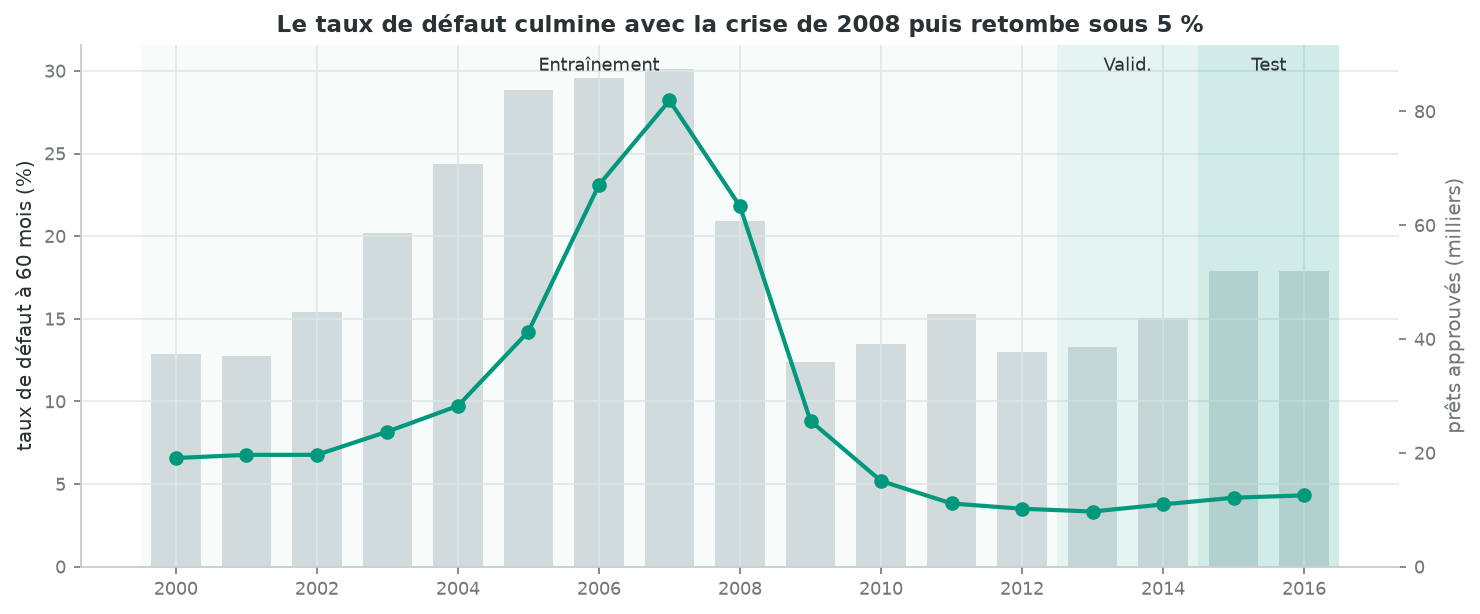

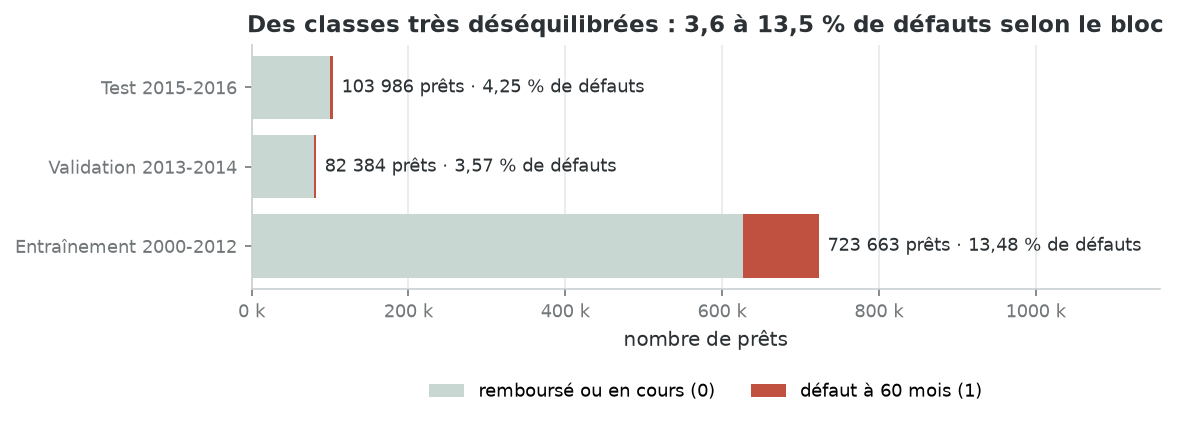

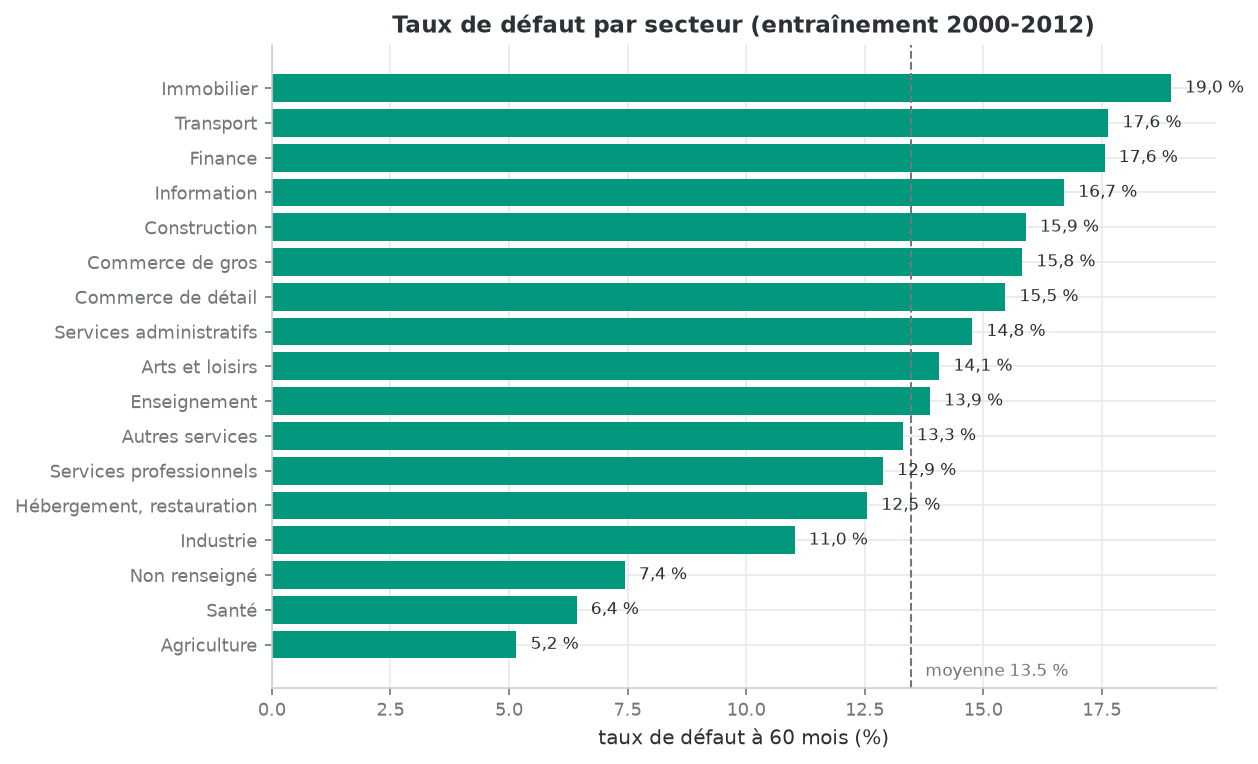

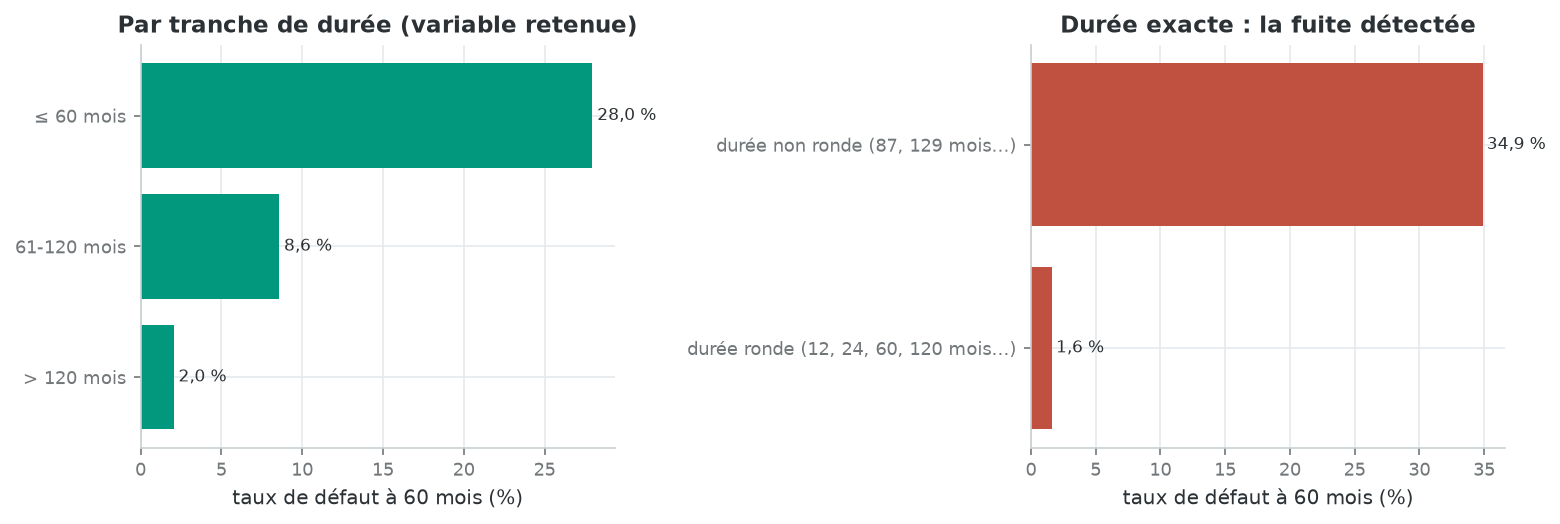

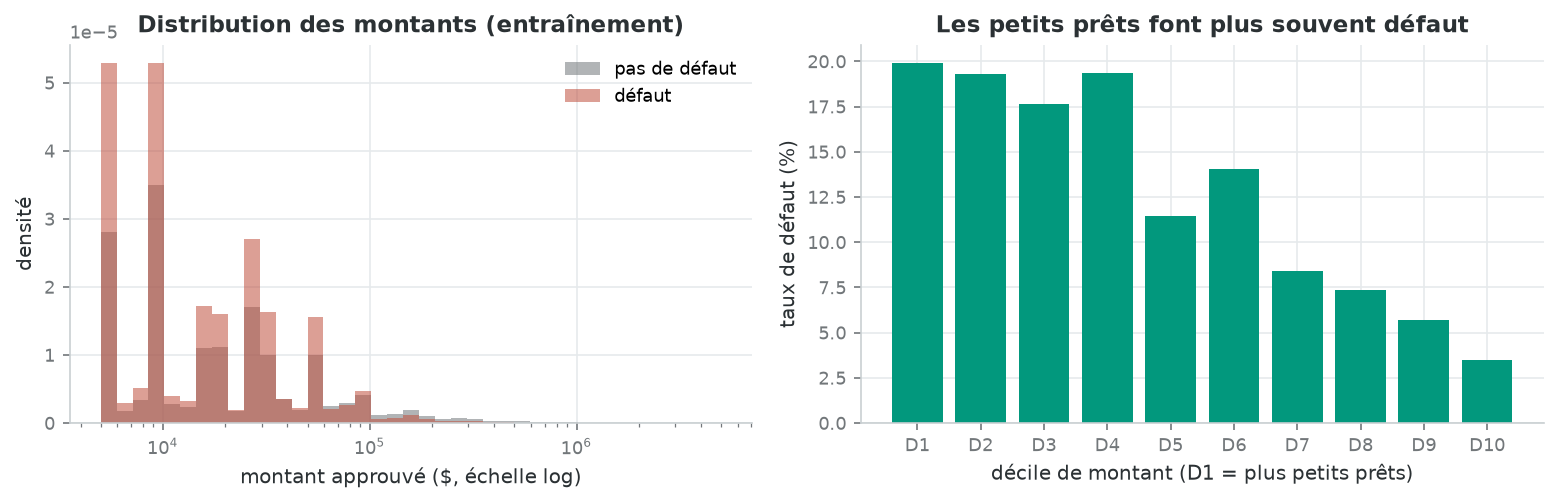

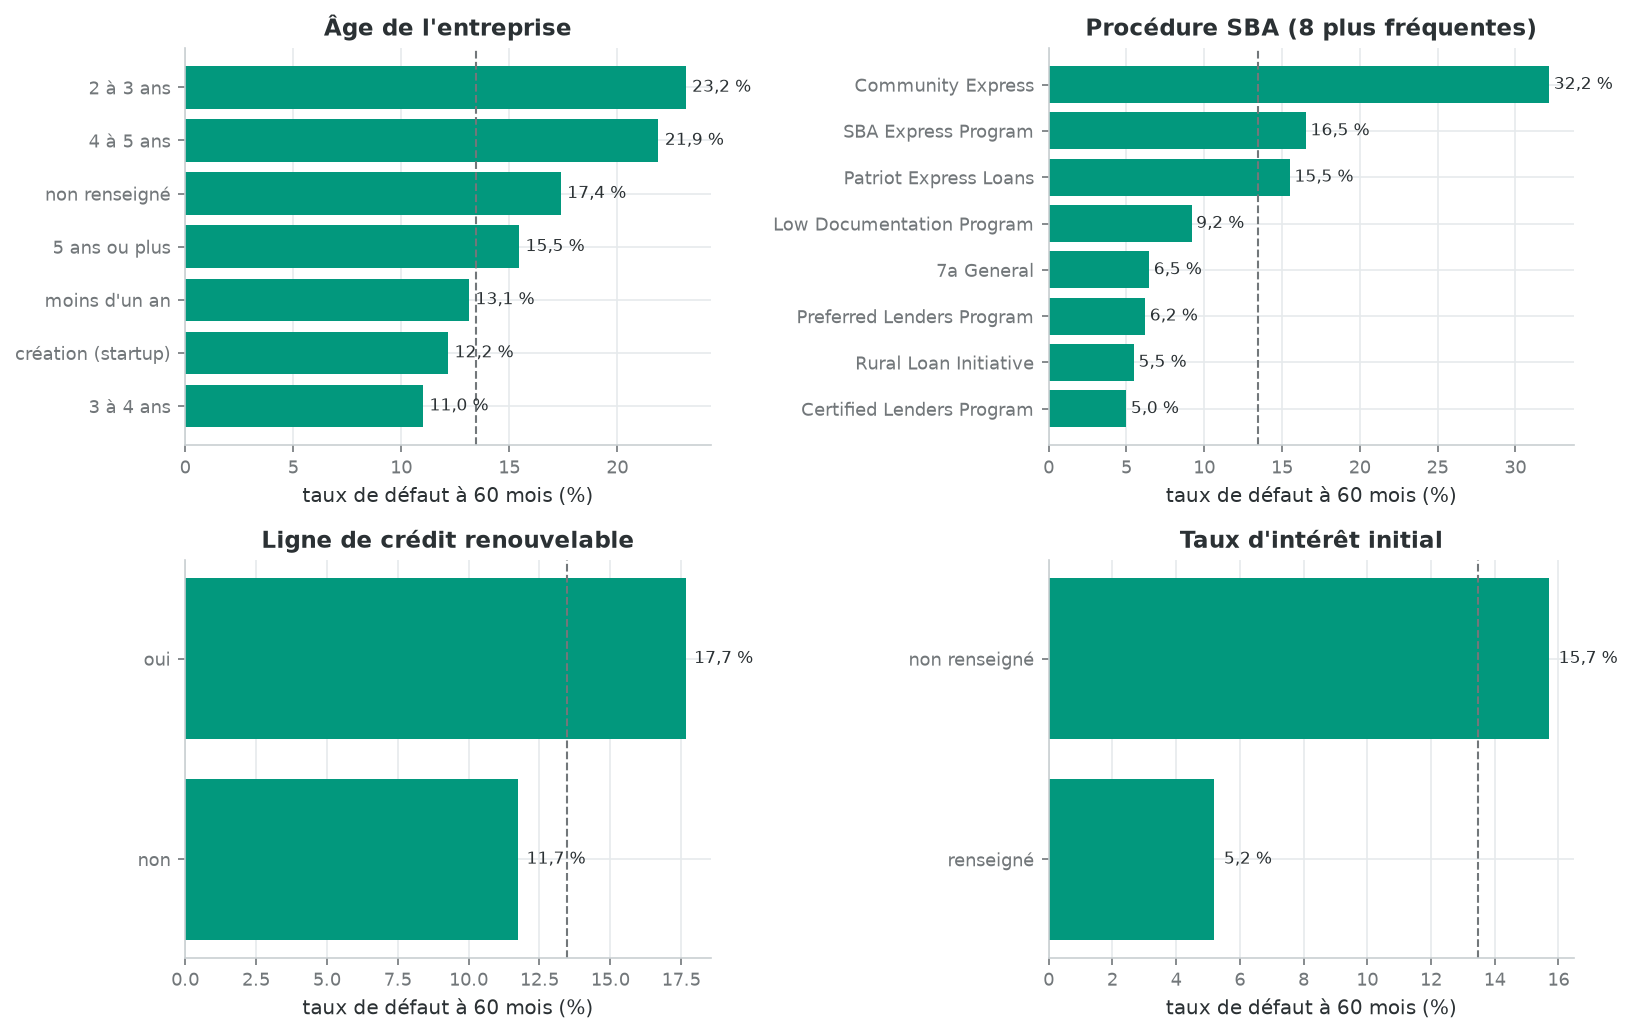

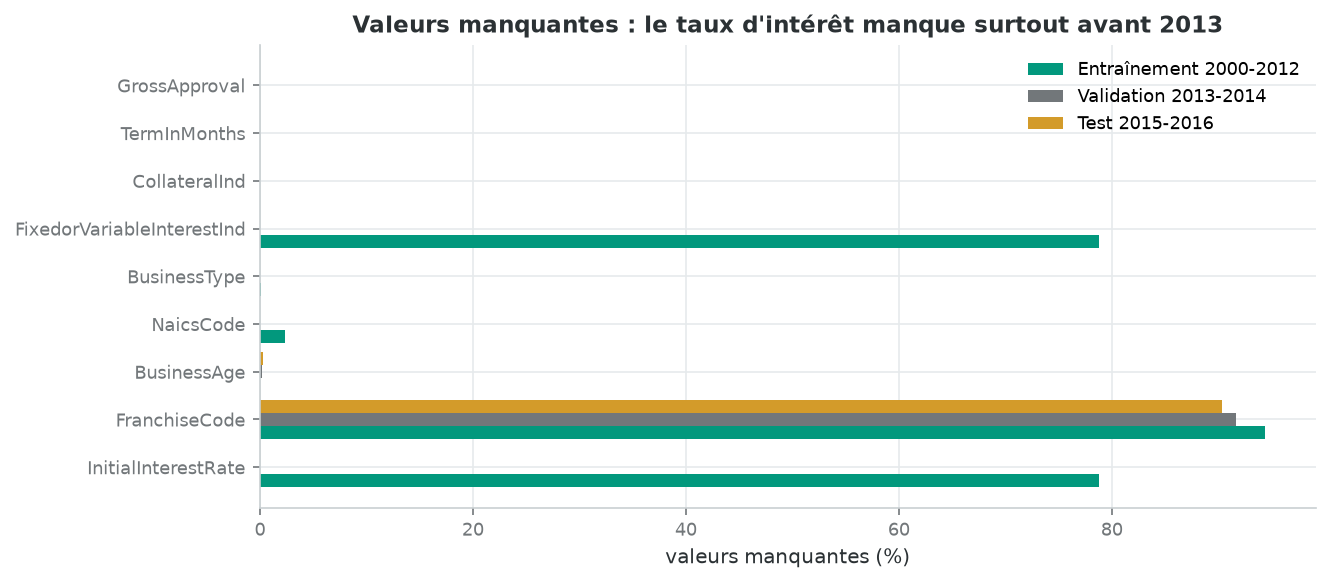

In [6]:
from IPython.display import Image, display
for f in ['fig_defaut_par_annee', 'fig_desequilibre', 'fig_defaut_par_secteur', 'fig_duree', 'fig_montant',
          'fig_variables_categorielles', 'fig_valeurs_manquantes']:
    display(Image(f'../reports/eda/{f}.png'))